# Análise de PIX por Habitante

## Integração de dados do Banco Central e IBGE

Nesta análise serão relacionados os dados de transações PIX por município,
disponibilizados pelo Banco Central do Brasil, com as estimativas populacionais
dos municípios brasileiros disponibilizadas pelo IBGE.

O objetivo é criar indicadores que permitam comparar a utilização do PIX
entre municípios de diferentes tamanhos populacionais.

In [62]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [5]:
import sys
print(sys.executable)

c:\Users\Opale\AppData\Local\Programs\Python\Python314\python.exe


In [6]:
import sys
!"{sys.executable}" -m pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]




[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import openpyxl

print(openpyxl.__version__)

3.1.5


In [3]:
arquivo_ibge = "../data/raw/estimativa_dou_2026.xlsx"

excel_ibge = pd.ExcelFile(arquivo_ibge)

excel_ibge.sheet_names

['br_uf', 'municípios']

In [6]:
populacao = pd.read_excel(
    arquivo_ibge, 
    sheet_name="municípios", 
    header=1
)

populacao.head()

,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,POPULAÇÃO ESTIMADA
0,RO,11.0,15.0,Alta Floresta D'Oeste,22724.0
1,RO,11.0,23.0,Ariquemes,109731.0
2,RO,11.0,31.0,Cabixi,5640.0
3,RO,11.0,49.0,Cacoal,98884.0
4,RO,11.0,56.0,Cerejeiras,16957.0


In [7]:
populacao.columns

Index(['UF', 'COD. UF', 'COD. MUNIC', 'NOME DO MUNICÍPIO',
       'POPULAÇÃO ESTIMADA'],
      dtype='str')

## 2. Preparação dos dados do IBGE

A base do IBGE possui o código da Unidade da Federação e o código do município
em colunas separadas. Nesta etapa será criado o código IBGE completo do
município para permitir a integração com os dados do Banco Central.

In [9]:
populacao[["COD. UF", "COD. MUNIC", "NOME DO MUNICÍPIO",]].head(10)

,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO
0,11.0,15.0,Alta Floresta D'Oeste
1,11.0,23.0,Ariquemes
2,11.0,31.0,Cabixi
3,11.0,49.0,Cacoal
4,11.0,56.0,Cerejeiras
5,11.0,64.0,Colorado do Oeste
6,11.0,72.0,Corumbiara
7,11.0,80.0,Costa Marques
8,11.0,98.0,Espigão D'Oeste
9,11.0,106.0,Guajará-Mirim


### Criação do código IBGE do município

O arquivo do IBGE apresenta o código da UF e o código do município em
colunas separadas. Os códigos serão padronizados e combinados para formar
o código IBGE completo de 7 dígitos.

In [34]:
populacao["COD. UF"] = pd.to_numeric(
    populacao["COD. UF"],
    errors="coerce"
).astype("Int64")

populacao["COD. MUNIC"] = pd.to_numeric(
    populacao["COD. MUNIC"],
    errors="coerce"
).astype("Int64")

populacao["Municipio_Ibge"] = (
    populacao["COD. UF"].astype("string").str.zfill(2)
    + populacao["COD. MUNIC"].astype("string").str.zfill(5)
).astype("Int64")

In [12]:
populacao[
    ["Municipio_ibge", "NOME DO MUNICÍPIO", "POPULAÇÃO ESTIMADA"]
].head(10)

,Municipio_ibge,NOME DO MUNICÍPIO,POPULAÇÃO ESTIMADA
0,1100015,Alta Floresta D'Oeste,22724.0
1,1100023,Ariquemes,109731.0
2,1100031,Cabixi,5640.0
3,1100049,Cacoal,98884.0
4,1100056,Cerejeiras,16957.0
5,1100064,Colorado do Oeste,16432.0
6,1100072,Corumbiara,7938.0
7,1100080,Costa Marques,13499.0
8,1100098,Espigão D'Oeste,32960.0
9,1100106,Guajará-Mirim,43633.0


In [13]:
pix = pd.read_parquet("../data/processed/dados_tratados.parquet")

pix["AnoMes"].value_counts().sort_index()

AnoMes
202501    4548
202502    4547
202503    4534
202504    4550
202505    4548
202506    4545
202507    4541
202508    4532
202509    4550
202510    4537
202511    4543
202512    4536
202601    4558
202602    4539
202603    4548
202604    4564
202605    4558
202606    4532
202607    4544
202608    4550
202609    4553
202610    4543
Name: count, dtype: int64

## 3. Definição do período da análise

Como a base do Banco Central possui dados mensais, será utilizado setembro de 2026
como período de referência.

A escolha de um único mês permite comparar os municípios utilizando o mesmo
período e relacionar os dados de transações PIX com a estimativa populacional
de 2026 do IBGE.

### 3.1 Extração dos dados PIX de setembro de 2026

A base utilizada anteriormente possuía um limite de 100.000 registros e abrangia
diversos meses, o que poderia resultar em uma amostra incompleta dos municípios.

Para garantir uma comparação adequada com a estimativa populacional do IBGE,
serão extraídos diretamente da API do Banco Central apenas os dados referentes
a setembro de 2026.

In [26]:
pix_setembro = pix_setembro[
    pix_setembro["AnoMes"] == 202609
    ].copy()

pix_setembro.shape

(5572, 19)

In [27]:
pix_setembro["AnoMes"].value_counts()

AnoMes
202609    5572
Name: count, dtype: int64

In [28]:
pix_setembro["Municipio_Ibge"].isna().sum()

np.int64(1)

In [29]:
pix_setembro[pix_setembro["Municipio_Ibge"].isna()]

,AnoMes,Municipio_Ibge,Municipio,Estado_Ibge,Estado,Sigla_Regiao,Regiao,VL_PagadorPF,QT_PagadorPF,VL_PagadorPJ,QT_PagadorPJ,VL_RecebedorPF,QT_RecebedorPF,VL_RecebedorPJ,QT_RecebedorPJ,QT_PES_PagadorPF,QT_PES_PagadorPJ,QT_PES_RecebedorPF,QT_PES_RecebedorPJ
3957,202609,NaN,N/D,NaN,NAO INFORMADO,NaN,Nao informado,1.610882e+09,3478925,1.109678e+10,1668982,1.759744e+09,2285567,5.567112e+09,937061,185673,1052,168361,1413


In [18]:
populacao["Municipio_ibge"].nunique()

5571

In [23]:
import pandas as pd

url_pix = (
    "https://olinda.bcb.gov.br/olinda/servico/Pix_DadosAbertos/versao/v1/odata/"
    "TransacoesPixPorMunicipio(DataBase=@DataBase)"
)

params = {
    "$format": "json",
    "@DataBase": "'202609'",
}

response = requests.get(
    url_pix,
    params=params,
    timeout=120
)

response.raise_for_status()

pix_setembro = pd.DataFrame(response.json()["value"])

In [24]:
print("Dimensão:", pix_setembro.shape)

print("\nMeses encontrados:")
print(pix_setembro["AnoMes"].value_counts())

print("\nMunicípios únicos:")
print(pix_setembro["Municipio_Ibge"].nunique())

Dimensão: (11144, 19)

Meses encontrados:
AnoMes
202610    5572
202609    5572
Name: count, dtype: int64

Municípios únicos:
5571


In [25]:
pix_setembro.head()

,AnoMes,Municipio_Ibge,Municipio,Estado_Ibge,Estado,Sigla_Regiao,Regiao,VL_PagadorPF,QT_PagadorPF,VL_PagadorPJ,QT_PagadorPJ,VL_RecebedorPF,QT_RecebedorPF,VL_RecebedorPJ,QT_RecebedorPJ,QT_PES_PagadorPF,QT_PES_PagadorPJ,QT_PES_RecebedorPF,QT_PES_RecebedorPJ
0,202610,3201803.0,DIVINO DE SÃO LOURENÇO,32.0,ESPÍRITO SANTO,SE,SUDESTE,5732046.24,26588,2146592.97,1687,5128951.65,13414,2519888.88,5986,2485,176,2202,164
1,202610,3137502.0,LAGOA FORMOSA,31.0,MINAS GERAIS,SE,SUDESTE,37188160.68,100603,15248468.89,6929,35709871.56,59559,13452671.63,23380,9534,722,8531,682
2,202609,2600401.0,ÁGUA PRETA,26.0,PERNAMBUCO,NE,NORDESTE,80512508.61,703301,10508981.30,16699,73849895.41,426508,9235444.75,67864,16047,307,15792,284
3,202610,4310900.0,JACUTINGA,43.0,RIO GRANDE DO SUL,SU,SUL,3227501.52,10952,1530090.12,832,2655988.55,5049,1721874.99,2489,1619,154,1241,157
4,202609,5005152.0,JUTI,50.0,MATO GROSSO DO SUL,CO,CENTRO-OESTE,26618603.85,171504,10637195.50,11041,24898857.87,85679,10480723.21,37459,4350,287,4230,274


### 3.2 Tratamento de registros sem identificação municipal

Foi identificado um registro sem código IBGE e sem município informado.
Como a análise será realizada por município e por habitante, esse registro
não poderá ser relacionado à base populacional do IBGE e será removido
apenas desta etapa da análise.

In [30]:
pix_setembro = pix_setembro.dropna(
    subset=["Municipio_Ibge"]
).copy()

In [31]:
print("Linhas:", len(pix_setembro))
print("Municípios únicos:", pix_setembro["Municipio_Ibge"].nunique())

Linhas: 5571
Municípios únicos: 5571


## 4. Integração dos dados do Banco Central com o IBGE

Nesta etapa, os dados de transações PIX de setembro de 2026 serão relacionados
com a estimativa populacional dos municípios brasileiros.

A integração será realizada utilizando o código IBGE do município como chave
de relacionamento entre as duas bases.

In [35]:
populacao_merge = populacao[
    [
        "Municipio_Ibge",
        "NOME DO MUNICÍPIO",
        "POPULAÇÃO ESTIMADA"
    ]
].copy()

In [36]:
populacao_merge.head()

,Municipio_Ibge,NOME DO MUNICÍPIO,POPULAÇÃO ESTIMADA
0,1100015,Alta Floresta D'Oeste,22724.0
1,1100023,Ariquemes,109731.0
2,1100031,Cabixi,5640.0
3,1100049,Cacoal,98884.0
4,1100056,Cerejeiras,16957.0


In [37]:
dados_completos = pix_setembro.merge(
    populacao_merge,
    on="Municipio_Ibge",
    how="left"
)

In [38]:
dados_completos.shape

(5571, 21)

In [39]:
dados_completos["POPULAÇÃO ESTIMADA"].isna().sum()

np.int64(0)

In [40]:
dados_completos[
    [
        "Municipio_Ibge",
        "Municipio",
        "NOME DO MUNICÍPIO",
        "POPULAÇÃO ESTIMADA"
    ]
].head(10)

,Municipio_Ibge,Municipio,NOME DO MUNICÍPIO,POPULAÇÃO ESTIMADA
0,2600401.0,ÁGUA PRETA,Água Preta,26760.0
1,5005152.0,JUTI,Juti,7122.0
2,2210904.0,SOCORRO DO PIAUÍ,Socorro do Piauí,4148.0
3,5107800.0,SANTO ANTÔNIO DO LEVERGER,Santo Antônio de Leverger,16882.0
4,5101837.0,BOA ESPERANÇA DO NORTE,Boa Esperança do Norte,5983.0
5,2208601.0,PRATA DO PIAUÍ,Prata do Piauí,3094.0
6,3302908.0,MIGUEL PEREIRA,Miguel Pereira,28151.0
7,1716653.0,PEQUIZEIRO,Pequizeiro,5032.0
8,2704708.0,MARECHAL DEODORO,Marechal Deodoro,62528.0
9,2915908.0,ITANAGRA,Itanagra,6069.0


## 5. Criação de indicadores por habitante

Após a integração das bases, serão criados indicadores que permitem comparar
municípios com diferentes tamanhos populacionais.

Para evitar dupla contagem entre pagamentos enviados e recebidos, nesta análise
serão utilizadas as informações referentes aos pagadores, considerando pessoas
físicas e jurídicas.

Serão calculados:

- valor de PIX enviado por habitante;
- quantidade de transações PIX enviadas por habitante.

In [41]:
dados_completos["Municipio_Ibge"] = (
    dados_completos["Municipio_Ibge"].astype("Int64")
)

dados_completos["POPULAÇÃO ESTIMADA"] = (
    dados_completos["POPULAÇÃO ESTIMADA"].astype("Int64")
)

In [42]:
dados_completos["VL_PIX_ENVIADO"] = (
    dados_completos["VL_PagadorPF"] 
    + dados_completos["VL_PagadorPJ"]
)

dados_completos["QT_PIX_ENVIADO"] = (
    dados_completos["QT_PagadorPF"]
    + dados_completos["QT_PagadorPJ"]
)

In [46]:
dados_completos["VALOR_PIX_POR_HABITANTE"] = (
    dados_completos["VL_PIX_ENVIADO"]
    / dados_completos["POPULAÇÃO ESTIMADA"]
)

dados_completos["QT_PIX_POR_HABITANTE"] = (
    dados_completos["QT_PIX_ENVIADO"]
    / dados_completos["POPULAÇÃO ESTIMADA"]
)

In [47]:
dados_completos[
    [
        "Municipio",
        "Estado",
        "POPULAÇÃO ESTIMADA",
        "VL_PIX_ENVIADO",
        "QT_PIX_ENVIADO",
        "VALOR_PIX_POR_HABITANTE",
        "QT_PIX_POR_HABITANTE"
    ]

].head(10)

,Municipio,Estado,POPULAÇÃO ESTIMADA,VL_PIX_ENVIADO,QT_PIX_ENVIADO,VALOR_PIX_POR_HABITANTE,QT_PIX_POR_HABITANTE
0,ÁGUA PRETA,PERNAMBUCO,26760,9.102149e+07,720000,3401.400968,26.90583
1,JUTI,MATO GROSSO DO SUL,7122,3.725580e+07,182545,5231.086682,25.631143
2,SOCORRO DO PIAUÍ,PIAUÍ,4148,1.585801e+07,110224,3823.049188,26.572806
3,SANTO ANTÔNIO DO LEVERGER,MATO GROSSO,16882,1.038527e+08,478793,6151.681271,28.361154
4,BOA ESPERANÇA DO NORTE,MATO GROSSO,5983,5.660004e+07,39269,9460.142918,6.56343
5,PRATA DO PIAUÍ,PIAUÍ,3094,1.042788e+07,97883,3370.355023,31.636393
6,MIGUEL PEREIRA,RIO DE JANEIRO,28151,2.453770e+08,861326,8716.456084,30.59664
7,PEQUIZEIRO,TOCANTINS,5032,3.657973e+07,120024,7269.421439,23.852146
8,MARECHAL DEODORO,ALAGOAS,62528,5.698566e+08,2132466,9113.623313,34.104177
9,ITANAGRA,BAHIA,6069,3.327804e+07,246272,5483.282457,40.578679


### 5.1 Análise da distribuição dos indicadores

Antes da criação dos rankings, será analisada a distribuição dos indicadores
por habitante. Essa etapa permite identificar valores muito acima do padrão
e evitar interpretações equivocadas causadas por municípios com características
econômicas ou populacionais muito específicas.

In [48]:
dados_completos[
    "VALOR_PIX_POR_HABITANTE"
].quantile([0.50, 0.75, 0.90, 0.95, 0.99])

0.50     5692.908648
0.75     8317.457593
0.90    12199.876279
0.95    15621.841907
0.99    33906.440077
Name: VALOR_PIX_POR_HABITANTE, dtype: Float64

In [51]:
dados_completos[
    [
        "Municipio",
        "Estado",
        "POPULAÇÃO ESTIMADA",
        "VALOR_PIX_POR_HABITANTE",
        "QT_PIX_POR_HABITANTE"
    ]
].sort_values(
    "VALOR_PIX_POR_HABITANTE",
    ascending=False
).head(10)

,Municipio,Estado,POPULAÇÃO ESTIMADA,VALOR_PIX_POR_HABITANTE,QT_PIX_POR_HABITANTE
3815,SANTO ANTÔNIO DE LISBOA,PIAUÍ,5923,481696.043282,1568.929428
4909,MONTE BELO,MINAS GERAIS,13353,175540.077219,46.461694
128,ÁGUA SANTA,RIO GRANDE DO SUL,4003,164467.213985,519.945291
4314,BARUERI,SÃO PAULO,336015,154857.059768,90.547949
2602,ÁGUAS FRIAS,SANTA CATARINA,3036,129730.406838,14.213109
4454,BELA VISTA DO PARAÍSO,PARANÁ,14967,129034.068974,816.998864
146,SANTA BÁRBARA DO SUL,RIO GRANDE DO SUL,8268,125566.396313,20.097121
4311,SARANDI,PARANÁ,130211,121630.184709,27.640507
2646,CUITÉ,PARAÍBA,20210,119437.606896,950.75235
3709,ROCHEDO,MATO GROSSO DO SUL,5494,103033.890224,31.505096


### 5.2 Identificação de valores extremos

A análise inicial revelou municípios com valores de PIX por habitante muito
superiores ao restante da distribuição.

Esses registros serão mantidos na base, pois podem representar características
econômicas reais dos municípios. Entretanto, serão identificados como valores
extremos para evitar que distorçam as comparações entre municípios.

In [52]:
limite_99 = dados_completos[
    "VALOR_PIX_POR_HABITANTE"
].quantile(0.99)

limite_99

np.float64(33906.440076971805)

In [53]:
dados_completos["OUTLIER_VALOR_PIX"] =(
    dados_completos["VALOR_PIX_POR_HABITANTE"] > limite_99
)

In [54]:
dados_completos["OUTLIER_VALOR_PIX"].value_counts()

OUTLIER_VALOR_PIX
False    5515
True       56
Name: count, dtype: Int64

### 5.3 Classificação dos municípios por população

Para permitir comparações mais equilibradas, os municípios serão agrupados
de acordo com o tamanho da população estimada.

In [55]:
dados_completos["PORTE_MUNICIPIO"] = pd.cut(
    dados_completos["POPULAÇÃO ESTIMADA"],
    bins=[0, 10000, 50000, 100000, 500000, float("inf")],
    labels=[
        "Até 10 mil habitantes",
        "De 10 mil a 50 mil habitantes",
        "De 50 mil a 100 mil habitantes",
        "De 100 mil a 500 mil habitantes",
        "Acima de 500 mil habitantes"
    ]
)

In [56]:
dados_completos["PORTE_MUNICIPIO"].value_counts().sort_index()

PORTE_MUNICIPIO
Até 10 mil habitantes              2467
De 10 mil a 50 mil habitantes      2417
De 50 mil a 100 mil habitantes      349
De 100 mil a 500 mil habitantes     289
Acima de 500 mil habitantes          49
Name: count, dtype: int64

## 6. Rankings de utilização do PIX

Nesta etapa serão analisados os municípios com maior movimentação de PIX
por habitante.

Como foram identificados valores extremos na distribuição, o ranking principal
será apresentado sem os municípios classificados acima do percentil 99.
Os registros não serão excluídos da base original, apenas desconsiderados
nesta comparação.

In [57]:
dados_sem_outliers = dados_completos[
    dados_completos["OUTLIER_VALOR_PIX"] == False
].copy()

dados_sem_outliers.shape

(5515, 27)

In [58]:
ranking_valor = dados_sem_outliers[
    [
        "Municipio",
        "Estado",
        "POPULAÇÃO ESTIMADA",
        "PORTE_MUNICIPIO",
        "VALOR_PIX_POR_HABITANTE",
        "QT_PIX_POR_HABITANTE"
    ]
].sort_values(
    "VALOR_PIX_POR_HABITANTE",
    ascending=False
).head(10)

ranking_valor

,Municipio,Estado,POPULAÇÃO ESTIMADA,PORTE_MUNICIPIO,VALOR_PIX_POR_HABITANTE,QT_PIX_POR_HABITANTE
1063,PORTO REAL,RIO DE JANEIRO,21101,De 10 mil a 50 mil habitantes,33873.873264,31.674944
4493,CIANORTE,PARANÁ,83579,De 50 mil a 100 mil habitantes,33414.179546,23.613862
152,BEBEDOURO,SÃO PAULO,78298,De 50 mil a 100 mil habitantes,33094.048664,30.418823
3029,BARBOSA,SÃO PAULO,5598,Até 10 mil habitantes,33080.519778,36.101286
5347,PARANAPANEMA,SÃO PAULO,19901,De 10 mil a 50 mil habitantes,32663.465305,26.237978
5217,EUSÉBIO,CEARÁ,83641,De 50 mil a 100 mil habitantes,32477.561035,36.831506
1710,CURITIBA,PARANÁ,1832183,Acima de 500 mil habitantes,32347.345984,51.223556
790,TAPURAH,MATO GROSSO,16001,De 10 mil a 50 mil habitantes,32133.734337,25.955003
2313,SENADOR GUIOMARD,ACRE,22447,De 10 mil a 50 mil habitantes,32127.871888,35.642046
2737,BOFETE,SÃO PAULO,10735,De 10 mil a 50 mil habitantes,32064.086036,22.796926


In [59]:
ranking_quantidade = dados_sem_outliers[
    [
        "Municipio",
        "Estado",
        "POPULAÇÃO ESTIMADA",
        "PORTE_MUNICIPIO",
        "VALOR_PIX_POR_HABITANTE",
        "QT_PIX_POR_HABITANTE"
    ]
].sort_values(
    "QT_PIX_POR_HABITANTE",
    ascending=False
).head(10)

ranking_quantidade

,Municipio,Estado,POPULAÇÃO ESTIMADA,PORTE_MUNICIPIO,VALOR_PIX_POR_HABITANTE,QT_PIX_POR_HABITANTE
414,MAMBORÊ,PARANÁ,13519,De 10 mil a 50 mil habitantes,9844.76254,149.996228
2303,ARARAS,SÃO PAULO,136113,De 100 mil a 500 mil habitantes,27043.5742,144.454821
2845,VERA CRUZ DO OESTE,PARANÁ,8131,Até 10 mil habitantes,17965.953252,110.748493
3587,PATO BRANCO,PARANÁ,99041,De 50 mil a 100 mil habitantes,26416.94155,83.548116
821,MOCAJUBA,PARÁ,28982,De 10 mil a 50 mil habitantes,5811.579925,56.701159
5205,VIÇOSA DO CEARÁ,CEARÁ,63316,De 50 mil a 100 mil habitantes,8763.878039,56.373255
478,MANAUS,AMAZONAS,2327101,Acima de 500 mil habitantes,15298.050563,53.772636
1710,CURITIBA,PARANÁ,1832183,Acima de 500 mil habitantes,32347.345984,51.223556
2392,BELÉM,PARÁ,1396157,Acima de 500 mil habitantes,10726.81636,51.001852
2141,SANTARÉM,PARÁ,364298,De 100 mil a 500 mil habitantes,9088.947634,50.890279


## 7. Visualização dos resultados

Os gráficos a seguir apresentam os municípios com maiores indicadores de
utilização do PIX por habitante, desconsiderando os valores classificados
como extremos na análise anterior.

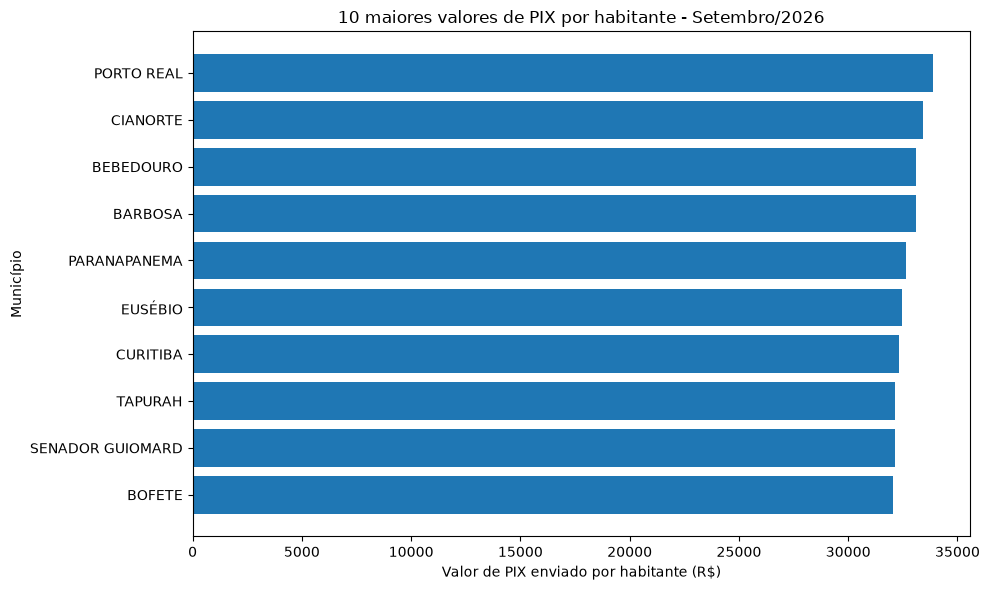

In [63]:
plt.figure(figsize=(10, 6))

plt.barh(
    ranking_valor["Municipio"],
    ranking_valor["VALOR_PIX_POR_HABITANTE"]
)

plt.xlabel("Valor de PIX enviado por habitante (R$)")
plt.ylabel("Município")
plt.title("10 maiores valores de PIX por habitante - Setembro/2026")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

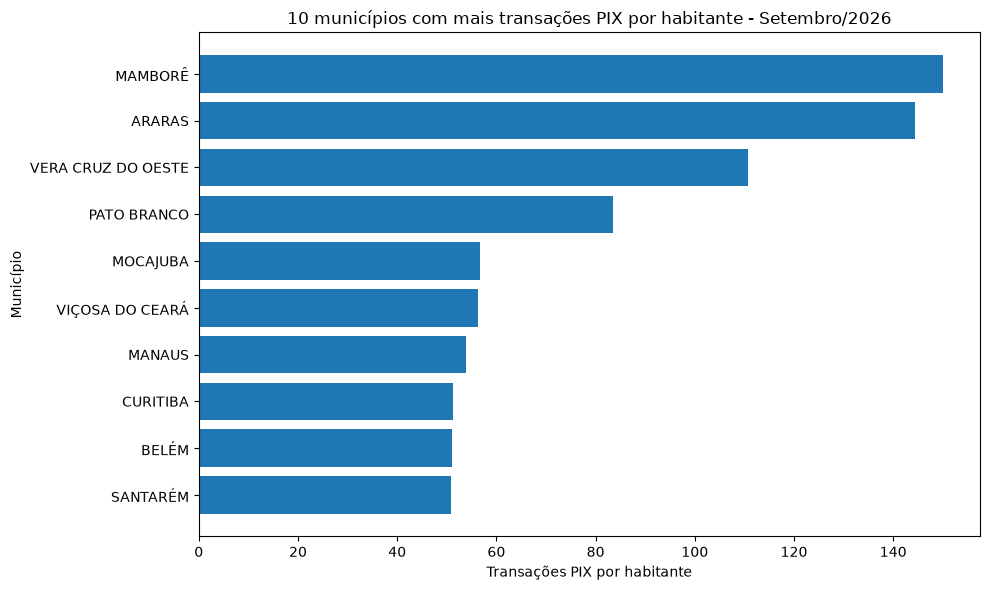

In [65]:
plt.figure(figsize=(10, 6))

plt.barh(
    ranking_quantidade["Municipio"],
    ranking_quantidade["QT_PIX_POR_HABITANTE"]
)

plt.xlabel("Transações PIX por habitante")
plt.ylabel("Município")
plt.title("10 municípios com mais transações PIX por habitante - Setembro/2026")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 8. Conclusão

A integração dos dados do Banco Central com as estimativas populacionais do
IBGE permitiu comparar a utilização do PIX entre os 5.571 municípios brasileiros
em setembro de 2026.

Durante a análise foram identificados valores extremos de movimentação por
habitante. Esses registros foram preservados na base original, mas os municípios
acima do percentil 99 foram desconsiderados nos rankings principais para evitar
distorções na comparação.

Entre os municípios considerados no ranking, Porto Real (RJ) apresentou o maior
valor de PIX enviado por habitante, enquanto Mamborê (PR) apresentou a maior
quantidade de transações por habitante.

Os resultados também demonstram que valor movimentado e quantidade de
transações representam comportamentos diferentes. Um município pode apresentar
grande volume financeiro sem necessariamente possuir a maior quantidade de
operações.

O projeto demonstrou um fluxo completo de análise de dados, incluindo extração
por API, tratamento, integração de diferentes fontes, identificação de valores
extremos, criação de indicadores e visualização dos resultados.

## 9. Exportação da base final

In [66]:
dados_completos.to_csv(
    "../data/processed/pix_populacao_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

dados_completos.to_parquet(
    "../data/processed/pix_populacao_2026.parquet",
    index=False
)

print("Arquivos salvos com sucesso.")

Arquivos salvos com sucesso.
